# 1. Importar librerias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# escalador de desviacion estandar
from sklearn.preprocessing import StandardScaler 
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 2. Cargar datos 

In [2]:
ruta = ("../data/raw/online_retail.csv")

datos_iniciales = pd.read_csv(ruta)

datos_iniciales.head(1)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom


# 3. Limpiar datos

In [3]:
datos_iniciales.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [4]:
datos_iniciales.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [5]:
datos_sin_nulos = datos_iniciales.dropna().copy()
datos_sin_duplicados = datos_sin_nulos.drop_duplicates().copy()
datos_sin_duplicados.shape

(401604, 8)

In [6]:
datos_sin_negativos = datos_sin_duplicados[datos_sin_duplicados["Quantity"] > 0].copy()
datos_positivos = datos_sin_negativos[datos_sin_negativos["UnitPrice"]>=1].copy()
datos_positivos.shape

(301022, 8)

# 4. Transformar tipos de datos

In [7]:
datos_limpios = datos_positivos.copy()

datos_limpios["InvoiceDate"] = pd.to_datetime(datos_limpios["InvoiceDate"])

datos_limpios.info()


<class 'pandas.DataFrame'>
Index: 301022 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    301022 non-null  str           
 1   StockCode    301022 non-null  str           
 2   Description  301022 non-null  str           
 3   Quantity     301022 non-null  int64         
 4   InvoiceDate  301022 non-null  datetime64[us]
 5   UnitPrice    301022 non-null  float64       
 6   CustomerID   301022 non-null  float64       
 7   Country      301022 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 20.7 MB


# 5. Variables calculadas 

In [8]:
datos_limpios["FechaInvoice"] = datos_limpios["InvoiceDate"].dt.date
datos_limpios["HoraInvoice"] = datos_limpios["InvoiceDate"].dt.time
datos_limpios["Monto_linea"] = datos_limpios["Quantity"] * datos_limpios["UnitPrice"]

datos_limpios.head(1)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,FechaInvoice,HoraInvoice,Monto_linea
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010-12-01,08:26:00,15.3


# opcional. Guardamos los datos limpios en un CSV nuevo

In [9]:
ruta_salida = "../data/processed/online_retail_limpios.csv"
datos_limpios.to_csv(ruta_salida)

# 6 Seleccionar variables

In [10]:
# Seleccionamos dos columnas que ya existen en el dataset.
variables = datos_limpios[["Quantity", "UnitPrice"]].copy()

print("Líneas de venta:", len(variables))
display(variables.head())


Líneas de venta: 301022


,Quantity,UnitPrice
0,6,2.55
1,6,3.39
2,8,2.75
3,6,3.39
4,6,3.39


### ¿Por qué Quantity y UnitPrice?
- **Quantity:** cantidad de unidades del producto en la línea de venta.
- **UnitPrice:** precio unitario del producto, en las unidades monetarias del archivo.

Estas dos columnas originales permiten distinguir compras de pocas o muchas unidades y artículos de precio bajo o alto. 

**Unidad de análisis:** una fila es una línea de factura. Segmentamos líneas de venta; una factura completa puede tener varias líneas y pertenecer a varios segmentos. Los resultados no son segmentos de clientes.

**Objetivo:** aplicar ln, estandarizar, comparar inercia y silueta e interpretar los grupos con las unidades originales.

# 7. Explorar las dos variables
Los histogramas permiten observar valores extremos y asimetría. Conservamos los valores extremos: no sabemos si son errores o compras reales. La limpieza anterior ya exige cantidades positivas y precios de al menos 1.

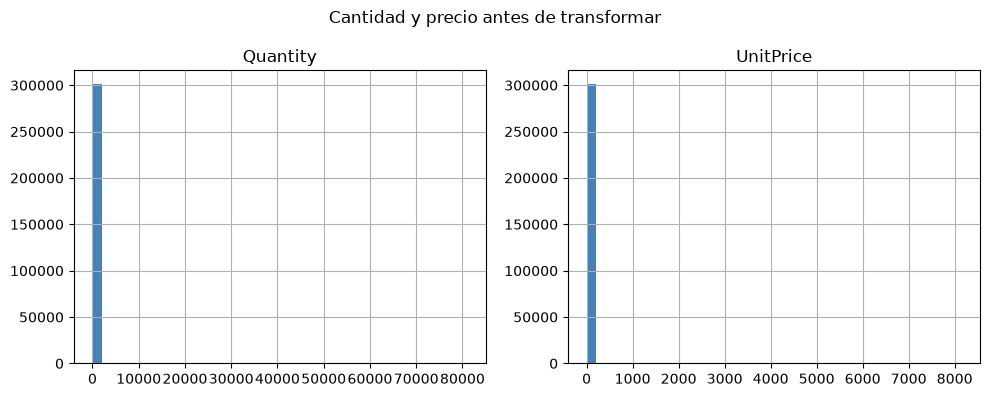

In [11]:
# ln solo se puede aplicar a valores positivos.
assert variables.notna().all().all(), "Hay valores faltantes."
assert (variables > 0).all().all(), "Hay valores cero o negativos."
assert np.isfinite(variables.to_numpy()).all(), "Hay valores infinitos."

variables.hist(bins=40, figsize=(10, 4), color="steelblue")
plt.suptitle("Cantidad y precio antes de transformar")
plt.tight_layout()
plt.show()

# 8. Aplicar logaritmo natural
`np.log()` calcula ln(x). Reduce la asimetría y comprime diferencias grandes. No garantiza que los datos sigan una distribución normal. No utilizamos `log1p` porque ambas variables son positivas.

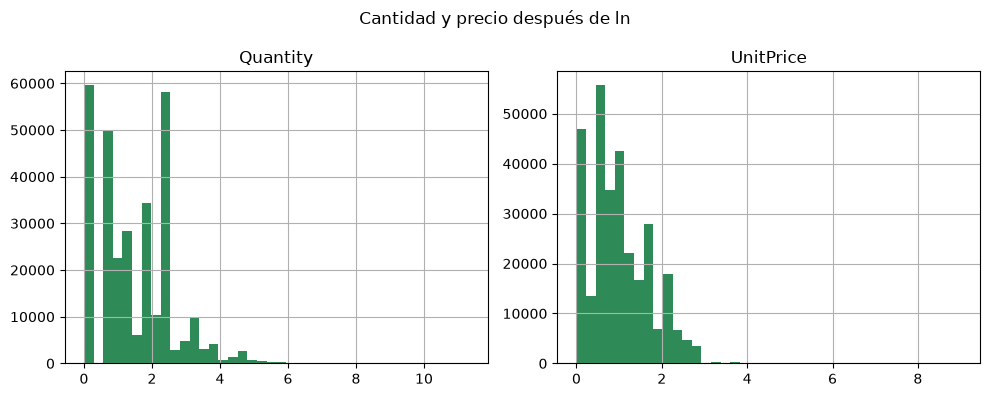

In [12]:
variables_log = np.log(variables)

variables_log.hist(bins=40, figsize=(10, 4), color="seagreen")
plt.suptitle("Cantidad y precio después de ln")
plt.tight_layout()
plt.show()

# 9. Estandarizar con StandardScaler
Después de ln, cada columna se transforma mediante `(valor - media) / desviación`. Así ambas variables tienen media cercana a 0 y desviación cercana a 1, y sus escalas no dominan la distancia.

El orden es **seleccionar columnas → ln → StandardScaler → K-means**. Las tablas transformadas contienen las mismas dos variables, sin crear indicadores de negocio nuevos.

In [13]:
escalador = StandardScaler()
variables_escaladas = escalador.fit_transform(variables_log)

print("Medias:", variables_escaladas.mean(axis=0).round(4))
print("Desviaciones:", variables_escaladas.std(axis=0).round(4))

Medias: [-0.  0.]
Desviaciones: [1. 1.]


# 10. Probar distintos valores de k
**Inercia:** suma de distancias al cuadrado al centroide asignado. Disminuye al aumentar k. Buscamos un codo donde la mejora adicional empieza a reducirse.

**Silueta:** compara la cercanía a su propio grupo con la cercanía a otros grupos. Va de −1 a 1. Cuanto mayor sea, mejor separados están los grupos; valores negativos indican asignaciones ambiguas. No se calcula para k=1.

Ajustamos K-means con **todas las filas** para k=1…8. Para evitar calcular distancias entre cientos de miles de filas, evaluamos silueta sobre una **misma muestra aleatoria de hasta 2,000 filas**, con semilla fija. El resultado es una estimación. `n_init=10` prueba diez inicializaciones por modelo.

In [14]:
# La misma muestra se usa para comparar todos los valores de k.
muestra = variables.sample(n=min(2000, len(variables)), random_state=42)
muestra_log = np.log(muestra)
muestra_escalada = escalador.transform(muestra_log)

valores_k = range(2, 9)
inercias = []
siluetas = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    modelo.fit(variables_escaladas)
    inercias.append(modelo.inertia_)

    if k == 1:
        siluetas.append(np.nan)
    else:
        grupos_muestra = modelo.predict(muestra_escalada)
        valor_silueta = silhouette_score(muestra_escalada, grupos_muestra)
        siluetas.append(valor_silueta)

resultados = pd.DataFrame({"k": list(valores_k), "Inercia": inercias, "Silueta": siluetas})
display(resultados.round(4))

,k,Inercia,Silueta
0,2,334314.5318,0.4140
1,3,209465.6729,0.4427
2,4,161408.8931,0.4313
3,5,128888.2091,0.4386
4,6,106219.8490,0.4332
5,7,93957.8242,0.3868
6,8,83010.3513,0.4036


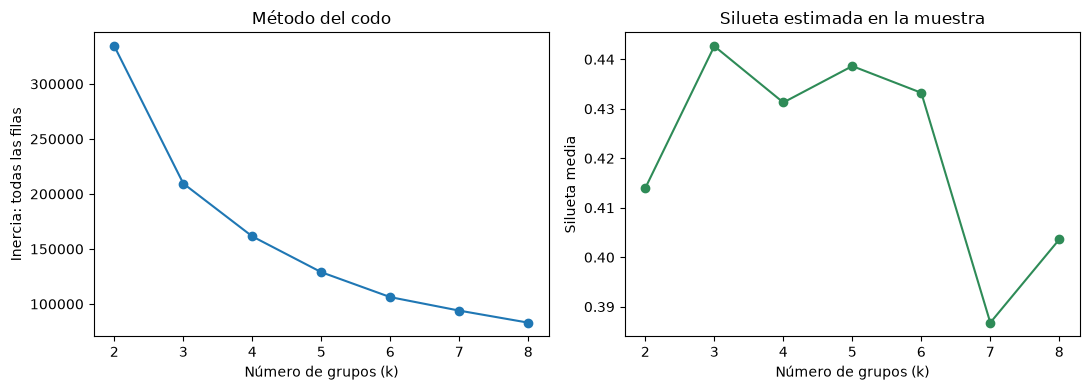

In [15]:
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(resultados["k"], resultados["Inercia"], marker="o")
plt.title("Método del codo")
plt.xlabel("Número de grupos (k)")
plt.ylabel("Inercia: todas las filas")
plt.xticks(list(valores_k))

plt.subplot(1, 2, 2)
plt.plot(resultados["k"], resultados["Silueta"], marker="o", color="seagreen")
plt.title("Silueta estimada en la muestra")
plt.xlabel("Número de grupos (k)")
plt.ylabel("Silueta media")
plt.xticks(list(valores_k))

plt.tight_layout()
plt.show()

# 11. Elegir k y ajustar el modelo final
Como regla inicial, elegimos el k con mayor silueta entre 2 y 8. Contrasta esa elección con el codo: ambos criterios pueden proponer diferentes niveles de detalle. El menor valor de inercia por sí solo no elige el mejor k.

Esta regla es reproducible y sencilla. No demuestra que exista un único número verdadero de segmentos. Puedes cambiar `mejor_k` para discutir otra solución en clase.

In [16]:
fila_mejor = resultados["Silueta"].idxmax()
mejor_k = int(resultados.loc[fila_mejor, "k"])
print("k elegido:", mejor_k)
print("Silueta estimada:", round(resultados.loc[fila_mejor, "Silueta"], 4))

modelo_final = KMeans(n_clusters=mejor_k, random_state=42, n_init=10)
grupos = modelo_final.fit_predict(variables_escaladas)

# La etiqueta es un resultado del modelo, no una tercera variable de entrada.
transacciones = variables.copy()
transacciones["Segmento"] = grupos

display(transacciones.head())

k elegido: 3
Silueta estimada: 0.4427


,Quantity,UnitPrice,Segmento
0,6,2.55,0
1,6,3.39,0
2,8,2.75,0
3,6,3.39,0
4,6,3.39,0


# 12. Visualizar los segmentos
Mostramos hasta 5,000 filas para que los puntos se puedan leer. La muestra se usa solo para dibujar; el modelo se ajustó con todas las filas.

En el gráfico derecho usamos los valores originales con ejes logarítmicos para visualizar mejor los extremos. Los números de segmento son etiquetas arbitrarias y no indican un orden de importancia.

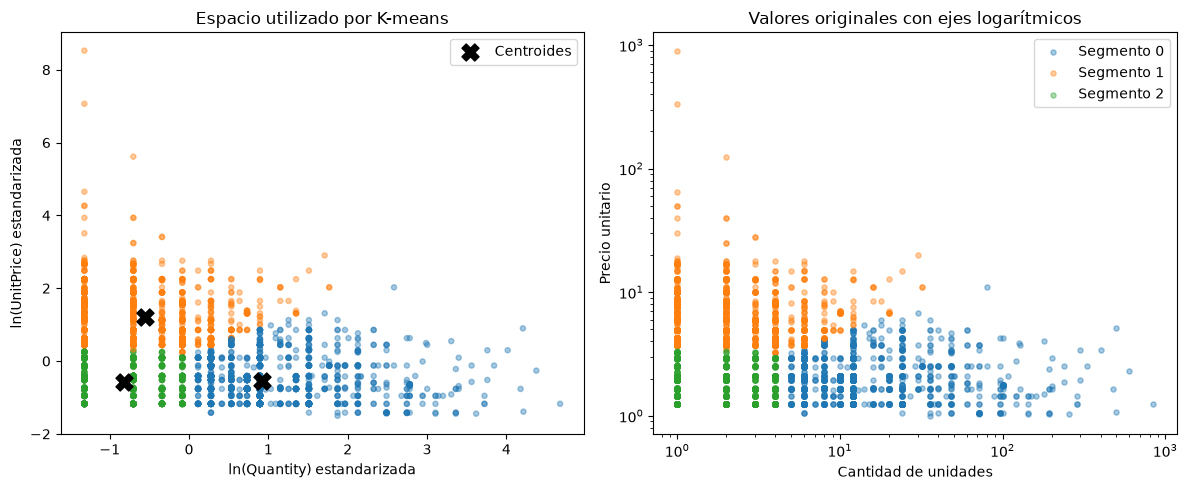

In [17]:
grafica = transacciones.sample(n=min(5000, len(transacciones)), random_state=42)
grafica_escalada = escalador.transform(np.log(grafica[["Quantity", "UnitPrice"]]))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(grafica_escalada[:, 0], grafica_escalada[:, 1],
            c=grafica["Segmento"], cmap="tab10", s=14, alpha=0.4, vmin=-0.5, vmax=9.5)
plt.scatter(modelo_final.cluster_centers_[:, 0], modelo_final.cluster_centers_[:, 1],
            color="black", marker="X", s=150, label="Centroides")
plt.title("Espacio utilizado por K-means")
plt.xlabel("ln(Quantity) estandarizada")
plt.ylabel("ln(UnitPrice) estandarizada")
plt.legend()

plt.subplot(1, 2, 2)
for segmento in range(mejor_k):
    puntos = grafica[grafica["Segmento"] == segmento]
    plt.scatter(puntos["Quantity"], puntos["UnitPrice"],
                s=14, alpha=0.4, color=plt.get_cmap("tab10")(segmento), label=f"Segmento {segmento}")
plt.xscale("log")
plt.yscale("log")
plt.title("Valores originales con ejes logarítmicos")
plt.xlabel("Cantidad de unidades")
plt.ylabel("Precio unitario")
plt.legend()

plt.tight_layout()
plt.show()

# 13. Describir los segmentos en unidades originales
Calculamos resúmenes **después** de segmentar, solo para interpretar. No agregan variables al modelo. Usamos medianas porque los extremos pueden distorsionar las medias.

El tamaño cuenta líneas de venta y su porcentaje se refiere al total de filas, no al total de clientes, facturas ni ingresos.

,Lineas,Cantidad_mediana,Precio_mediano,Cantidad_media,Precio_medio,Porcentaje_lineas
Segmento,,,,,,
0,127232,12.0,1.74,20.98,2.05,42.27
1,96001,2.0,5.79,3.07,7.90,31.89
2,77789,2.0,1.95,1.99,1.96,25.84


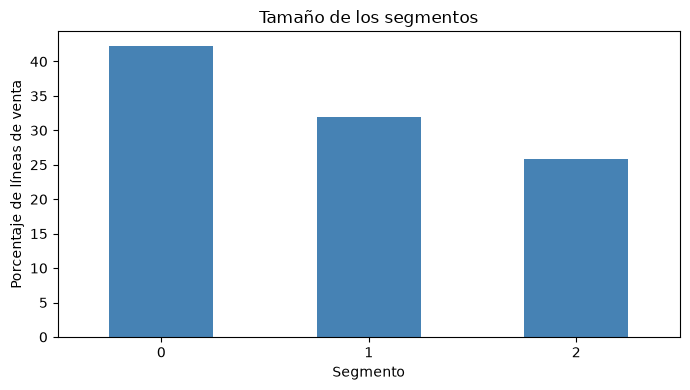

In [18]:
resumen = transacciones.groupby("Segmento").agg(
    Lineas=("Quantity", "size"),
    Cantidad_mediana=("Quantity", "median"),
    Precio_mediano=("UnitPrice", "median"),
    Cantidad_media=("Quantity", "mean"),
    Precio_medio=("UnitPrice", "mean")
)
resumen["Porcentaje_lineas"] = resumen["Lineas"] / len(transacciones) * 100

display(resumen.round(2))

resumen["Porcentaje_lineas"].plot(kind="bar", color="steelblue", rot=0, figsize=(7, 4))
plt.title("Tamaño de los segmentos")
plt.xlabel("Segmento")
plt.ylabel("Porcentaje de líneas de venta")
plt.tight_layout()
plt.show()

# 14. Actividades de la práctica
1. Explica qué representa una fila y por qué esta segmentación no describe clientes.
2. Compara los histogramas antes y después de ln, Qué cambio?. Explica también por qué  usamos StandardScaler.
3. Señala un posible codo y menciona la silueta de tres valores de k. Justifica como elegirías el k .
5. Como podrias explicar por qué un precio unitario alto no demuestra que una venta sea más rentable.



# 15. Interpretación final
El siguiente código describe cada grupo con los resultados obtenidos. “Menor”, “igual” y “mayor” se refieren a las medianas globales del archivo analizado.

In [19]:
cantidad_global = variables["Quantity"].median()
precio_global = variables["UnitPrice"].median()

print("Mediana global de cantidad:", cantidad_global)
print("Mediana global de precio:", precio_global)

for segmento in resumen.index:
    cantidad = resumen.loc[segmento, "Cantidad_mediana"]
    precio = resumen.loc[segmento, "Precio_mediano"]
    porcentaje = resumen.loc[segmento, "Porcentaje_lineas"]

    if cantidad > cantidad_global:
        nivel_cantidad = "mayor que la mediana global"
    elif cantidad < cantidad_global:
        nivel_cantidad = "menor que la mediana global"
    else:
        nivel_cantidad = "igual a la mediana global"

    if precio > precio_global:
        nivel_precio = "mayor que la mediana global"
    elif precio < precio_global:
        nivel_precio = "menor que la mediana global"
    else:
        nivel_precio = "igual a la mediana global"

    print(f"\nSegmento {segmento}: {porcentaje:.1f}% de las líneas de venta.")
    print(f"Cantidad típica: {cantidad:g} unidades; {nivel_cantidad}.")
    print(f"Precio unitario típico: {precio:.2f}; {nivel_precio}.")
    print("Lectura: este grupo reúne líneas con ese perfil de cantidad y precio.")

Mediana global de cantidad: 4.0
Mediana global de precio: 2.46

Segmento 0: 42.3% de las líneas de venta.
Cantidad típica: 12 unidades; mayor que la mediana global.
Precio unitario típico: 1.74; menor que la mediana global.
Lectura: este grupo reúne líneas con ese perfil de cantidad y precio.

Segmento 1: 31.9% de las líneas de venta.
Cantidad típica: 2 unidades; menor que la mediana global.
Precio unitario típico: 5.79; mayor que la mediana global.
Lectura: este grupo reúne líneas con ese perfil de cantidad y precio.

Segmento 2: 25.8% de las líneas de venta.
Cantidad típica: 2 unidades; menor que la mediana global.
Precio unitario típico: 1.95; menor que la mediana global.
Lectura: este grupo reúne líneas con ese perfil de cantidad y precio.


### Cómo interpretar el resultado comercial
Los grupos con más unidades y precios bajos pueden orientar el análisis de ventas por volumen. Los grupos con pocas unidades y precios altos pueden orientar el análisis del surtido de mayor precio. Los perfiles intermedios describen compras con niveles cercanos al centro del archivo. Son hipótesis de uso, no pruebas sobre la intención del comprador.

**Límites:** no usamos categoría de producto, país, cliente ni fecha. No podemos concluir lealtad, abandono o rentabilidad. Las líneas repetidas en cantidad y precio tienen más peso por aparecer más veces, lo cual es coherente con segmentar ventas observadas. La limpieza previa ya restringe la población y los extremos conservados aún pueden influir después de ln. La silueta es una estimación en una muestra, por lo que conviene repetirla con otra semilla si dos k tienen valores muy cercanos.

### Cierre con los resultados del CSV proporcionado
Se eligió **k=3**, con silueta estimada de **0.443**, frente a 0.414 para k=2 y 0.431 para k=4. La inercia baja aproximadamente 44.5% al pasar de 1 a 2 grupos, 37.3% de 2 a 3 y 22.9% de 3 a 4. La curva sugiere un codo alrededor de 3; junto con la mayor silueta y los perfiles legibles, respalda esta elección didáctica.

| Segmento | Porcentaje de líneas | Cantidad mediana | Precio unitario mediano | Interpretación |
|---|---:|---:|---:|---|
| 0 | 42.27% | 12 | 1.74 | Ventas de mayor cantidad y menor precio unitario; perfil de compra por volumen. |
| 1 | 31.89% | 2 | 5.79 | Ventas de pocas unidades y precio unitario relativamente alto. |
| 2 | 25.84% | 2 | 1.95 | Ventas de pocas unidades y precio unitario bajo. |

La distinción principal es que los segmentos 1 y 2 tienen cantidades típicas similares, pero precios diferentes; el segmento 0 destaca por una mayor cantidad. Esto permite explorar surtido, presentaciones por volumen y patrones de venta. No prueba que sean compras mayoristas, productos premium ni clientes de cierto tipo.

Estas cifras corresponden al CSV limpio proporcionado y a la ejecución guardada. Si se cambia la limpieza, la muestra o la semilla, se deben actualizar esta interpretación y las cifras a partir de las tablas anteriores. Los identificadores de grupo también pueden cambiar de orden.
